<h1 style="text-align: center"> City-cycle Fuel Consumption Analysis & Prediction </h1>
<h3 style="text-align: center; font-style: italic"> Garudapaksi Yusuf </h3>

---

**Table of Contents**
* [Section 1 | Data Preparation](#section-1--data-understanding)
    * [Data Context](#data-context)
    * [Data Dictionary](#data-dictionary)
    * [Data ETL](#data-etl)
    * [Train-Test Split](#train-test-split)
* [Section 2 | Data Analysis](#section-2--data-analysis)
    * [Initial Data Inspection](#initial-data-inspection)
        * [Missing Data](#missing-data)
        * [Invalid Data Type](#invalid-data-type)
    * [Final Data Inspection](#final-data-inspection)
    * [Visual Data Analysis](#visual-data-analysis)
    * [Analysis Summary](#analysis-summary)
    * [Data Anomaly](#data-anomaly)
        * [Variable Magnitude](#variable-magnitude)
        * [Outlier](#outlier)
        * [Cardinality](#cardinality)
* [Section 3 | Feature Engineering](#section-2--feature-engineering)
    * [Standardization](#standardization)
    * [Drop Rare Labels](#drop-rare-labels)

In [1]:
# import required library

# data understanding
from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.model_selection import train_test_split

# data analysis
import matplotlib.pyplot as plt
import seaborn as sns
from pyampute.exploration.mcar_statistical_tests import MCARTest
from feature_engine.imputation import DropMissingData
from feature_engine.preprocessing import MatchCategories

# feature engineering
from sklearn.preprocessing import StandardScaler
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder

---

## Section 1 | Data Preparation

### Data Context

<div align="center">

| <div style="width:170px"> Category </div> | Description |
| --- | --- |
| Source URL | [University of California, Irvine (UCI) Machine Learning Repository: "Auto MPG"](https://archive-beta.ics.uci.edu/dataset/9/auto+mpg) |
| Original Source URL | [Department of Statistics, Carnegie Mellon University (CMU) StatLib Datasets: "cars"](https://lib.stat.cmu.edu/datasets/) |
| License | [Creative Commons Attribution 4.0 International](https://creativecommons.org/licenses/by/4.0/legalcode) |
| Creation Date | July 7, 1993 |
| Number of Instances | 398 |
| Number of Attributes | 9 *(including the class attribute)* |
| Dataset Characteristics | Tabular, Multivariate |
| Associated Tasks | Regression |
| Feature Types | Continuous, Discrete, Categorical |


</div>

This dataset is a slightly modified version of the dataset provided in the StatLib library. In line with the use by [Quinlan (1993)](#reference) in predicting the attribute `mpg`, 8 of the original instances were removed because they had unknown values for the `mpg` attribute.

> The data concern city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multi-valued discrete and 5 continuous attributes. (Quinlan, 1993)

### Data Dictionary

<div align="center">

| No. | Variable | Role | Type | Description | Units | Missing Values |
| --- | --- | --- | --- | --- | --- | --- |
| <center> 1 </center> | `mpg` | Target | Continuous | *Miles per gallon* | - | <center> No </center> |
| <center> 2 </center> | `displacement` | Feature | Continuous | *Engine displacement* | *cu. inches* | <center> No </center> |
| <center> 3 </center> | `cylinders` | Feature | Integer | *Number of cylinders* | - | <center> No </center> |
| <center> 4 </center> | `horsepower` | Feature | Continuous | *Horsepower* | *hp* | <center> Yes </center> |
| <center> 5 </center> | `weight` | Feature | Continuous | *Weight* | *lbs.* | <center> No </center> |
| <center> 6 </center> | `acceleration` | Feature | Continuous | *Time to accelerate from 0 to 60 miles per hour* | *sec.* | <center> No </center> |
| <center> 7 </center> | `model_year` | Feature | Integer | *Model year* | *modulo 100* | <center> No </center> |
| <center> 8 </center> | `origin` | Feature | Integer | *Origin of car (1: American, 2: European, 3: Japanese)* | - | <center> No </center> |
| <center> 9 </center> | `car_name` | ID | Categorical | *Car manufacturer & type (unique for each instance)* | - | <center> No </center> |

</div>

### Data ETL

In [2]:
# fetch dataset
auto_mpg_id = 9
auto_mpg = fetch_ucirepo(id=auto_mpg_id)

# raw data (as Pandas dataframes)
features = auto_mpg.data.features
target = auto_mpg.data.targets
data_raw = pd.concat(
    objs=[features, target],
    axis=1
)

# show data samples
data_raw.sample(n=5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
42,383.0,8,180.0,4955,11.5,71,1,12.0
289,350.0,8,155.0,4360,14.9,79,1,16.9
77,121.0,4,76.0,2511,18.0,72,2,22.0
309,98.0,4,76.0,2144,14.7,80,2,41.5
107,232.0,6,100.0,2789,15.0,73,1,18.0


* Data succesfully **extracted** from the input source, **transformed** to the appropriate format, and **loaded** into the variable instance.
* Ditampilkan 5 sampel baris data dari dataset sebagai contoh hasil ETL:
    * Setiap baris dalam dataframe merepresentasikan satu *instance* dari car samples.
    * Sedangkan kolom dalam dataframe tersebut adalah *variabel* yang mewakili keragaman dari each samples.
        * Beberapa kolom berperan sebagai *feature*, yakni independent variable yang digunakan sebagai input dari suatu model machine learning, dan
        * Kolom pertama merupakan *target*, which is the variable that corresponds to the input data. 

### Train-Test Split

In [3]:
# set random state seed
RANDOM_STATE = 42

*Some scikit-learn `sklearn` objects are [inherently random](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness). The randomness of these objects is controlled via their `random_state` parameter.*
* *In order to obtain reproducible (i.e. constant) results across multiple executions of this project, the recommended way is by passing a random number generator `RandomState` instance to any of those objects that accept a `random_state` parameter.*
* *Random seed yang digunakan secara arbitrary dalam project ini adalah [42](https://en.wikipedia.org/wiki/42_(number)).*

In [4]:
def split_train_test(source):
    splitting = train_test_split(
        source,
        random_state=RANDOM_STATE
    )

    return splitting

In [5]:
# split data into random train and test subsets
data_train, data_test = split_train_test(source=data_raw)

# perform dimensionality analysis of train-test subsets
print("Data Dimensionality:")
pd.DataFrame(
    data=[(data_raw.shape[0], (data_raw.shape[0] / data_raw.shape[0]), data_raw.shape[1]),
          (data_train.shape[0], (data_train.shape[0] / data_raw.shape[0]), data_train.shape[1]),
          (data_test.shape[0], (data_test.shape[0] / data_raw.shape[0]), data_test.shape[1])],
    index=["data_raw", "data_train", "data_test"],
    columns=["row (n)", "row ratio", "column"]
)

Data Dimensionality:


,row (n),row ratio,column
data_raw,398,1.000000,8
data_train,298,0.748744,8
data_test,100,0.251256,8


* Tabel di atas mendeskripsikan dimensionality dari Auto MPG dataset setelah splitting dilakukan menjadi train dan test subsets:
    * Keseluruhan dataset terdiri dari `392` baris dan `8` kolom.
    * `train_test_split` membagi dataset tersebut menjadi `~0.75/75%` untuk data train dan `~0.25/25%` untuk data test, sesuai default parameter.
    * Splitting ini hanya membagi jumlah baris, sehingga jumlah kolom `8` adalah sama untuk tiap subset.
* Untuk memudahkan analisa dalam tahapan engineering ini, splitting hanya dilakukan menjadi dua bagian `data_train` dan `data_test`.
    * Appropriate splitting menjadi 4 bagian *X_train*, *X_test*, *y_train*, dan *y_test* akan dilakukan pada bagian-bagian selanjutnya.
    * Selain itu, feature engineering hanya akan berfokus pada `data_train` sebagai langkah tambahan untuk menghindari [data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

---

## Section 2 | Data Analysis

### Initial Data Inspection

In [6]:
# perform initial inspection on train set
pd.DataFrame(data={
    "dtype": data_train.dtypes,
    "sample": [data_train[column].unique() for column in data_train.columns],
    "min": [data_train[column].min() for column in data_train.columns],
    "max": [data_train[column].max() for column in data_train.columns],
    "duplicated": data_train.duplicated().sum(),
    "missing": data_train.isna().sum()
})

,dtype,sample,min,max,duplicated,missing
displacement,float64,"[98.0, 108.0, 199.0, 304.0, 250.0, 440.0, 97.0...",68.0,455.0,0,0
cylinders,int64,"[4, 6, 8, 3, 5]",3.0,8.0,0,0
horsepower,float64,"[66.0, 94.0, 97.0, 150.0, 105.0, 215.0, 46.0, ...",46.0,225.0,0,5
weight,int64,"[1800, 2379, 2774, 3672, 3459, 4312, 1835, 469...",1613.0,5140.0,0,0
acceleration,float64,"[14.4, 16.5, 15.5, 11.5, 16.0, 8.5, 20.5, 14.5...",8.0,24.8,0,0
model_year,int64,"[78, 73, 70, 72, 75, 74, 81, 76, 79, 82, 80, 7...",70.0,82.0,0,0
origin,int64,"[1, 3, 2]",1.0,3.0,0,0
mpg,float64,"[36.1, 22.0, 18.0, 17.0, 14.0, 26.0, 13.0, 33....",9.0,46.6,0,0


* Kolom `Dtype` menunjukkan jenis tipe data yang ada dalam `data_train`, yang seluruhnya memiliki tipe `float`:
    * Tipe data tersebut merepresentasikan random `Sample` yang ditunjukkan pada tiap variabel. Semisal `mpg` yang berisikan bilangan desimal `17.5`.
    * Namun domain knowledge mengindikasikan bahwa beberapa variabel tersebut sebenarnya memiliki **tipe data yang tidak sesuai**:
        * `cylinders & model_year` dengan deskripsi data jumlah silinder mesin dan tahun model dari city-cycle sewajarnya bertipe [ordinal](https://en.wikipedia.org/wiki/Ordinal_data), serta
        * `origin` dengan deskripsi origin of the car seharusnya bertipe [nominal](https://en.wikipedia.org/wiki/Level_of_measurement#Nominal_level).
* Tidak ada invalid data issue yang terdeteksi:
    * Rentang nilai yang ditunjukkan dari kolom `Min` dan ` Max` secara domain knowledge menunjukkan nilai yang valid, wajar, dan sebenarnya dari car samples.
    * Ambil contoh pada kolom `displacement`, a car's engine displacement bisa berada pada rentang nilai `70.0` hingga `455.0` cubic inches.
* Proses data inspection juga meliputi deteksi terhadap `Duplicated` & `Missing` data:
    * Tidak ada duplicated data yang terdeteksi —sebagaimana ditunjukkan pada nilai kolom `Duplicated` untuk seluruh variabel bernilai `0`—, tetapi
    * Terdeteksi adanya **missing data** pada beberapa variabel:
        * Sebagaimana ditunjukkan pada nilai kolom `Missing` untuk variabel `mpg & horsepower` masing-masing bernilai `7 & 5`.
        * Missing data [reduces the representativeness of the sample](https://en.wikipedia.org/wiki/Missing_data#Techniques_of_dealing_with_missing_data) and can therefore distort inferences about the population.
        * Khusus untuk kolom `mpg` —sesuai dengan informasi yang disampaikan pada [`Data Context`](#data-context)—, missing data pada kolom ini dapat diabaikan, dan tidak akan disertakan pada bagian-bagian analisis berikutnya.

#### Missing Data

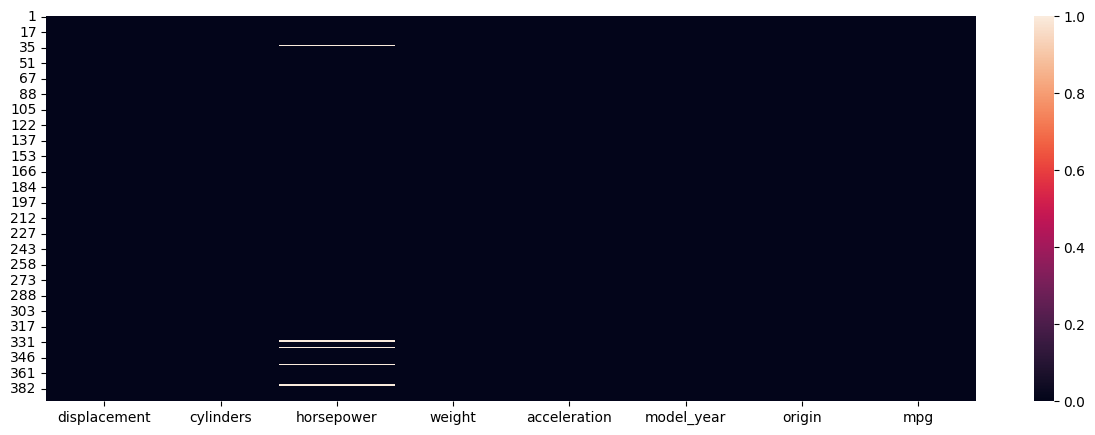

In [7]:
# plot heatmap consisting of missing data
width, height = 15, 5
_ = plt.figure(figsize=(width, height))

axes = sns.heatmap(data=data_train.isna().sort_index())
axes.set_xticklabels(
    labels=axes.get_xmajorticklabels(),
    rotation=0
)

plt.show()

* Heatmap di atas menunjukkan:
    * Garis berwarna putih pada kolom `horsepower` yang merepresentasikan missing data pada kolom tersebut, dan
    * Sumbu `y` menunjukkan lokasi (indeks) missing data tersebut dalam data.
* Dari visualisasi ini, dapat diinterpretasikan bahwa:
    * Missing data terletak pada lokasi yang acak pada `horsepower`;
    * Missing data terpisah satu sama lain, tidak berdekatan, berhimpitan maupun membentuk pola tertentu.

In [8]:
# slice missing data in train set
data_train[data_train["horsepower"].isnull()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
336,140.0,4,NaN,2905,14.3,80,1,23.6
374,151.0,4,NaN,3035,20.5,82,1,23.0
32,98.0,4,NaN,2046,19.0,71,1,25.0
354,100.0,4,NaN,2320,15.8,81,2,34.5
330,85.0,4,NaN,1835,17.3,80,2,40.9


* DataFrame di atas menunjukkan:
    * Sampel dengan missing data pada `horsepower`,
    * Nilai pada variabel lain dalam data dengan missing data tersebut, dan
    * Indeks dari missing data dalam data.
* A priori, dapat disimpulkan bahwa:
    * Tidak ada indikasi bahwa missing data tersebut are dependent on any other variable.
    * Ambil contoh dari kolom `displacement`: missing data memiliki nilai `displacement` yang beragam.

In [9]:
# perform Little's MCAR test
mcar_test = MCARTest(method="little")
mcar_test_pvalue = mcar_test.little_mcar_test(X=data_train)

*Little's MCAR Test (1988) adalah:*
* *Statistical hypothesis test untuk Missing Completely At Random (MCAR).*
    * *Null hypothesis: data is MCAR*
    * *Alternative hypothesis: data is not MCAR*
* *Metode yang digunakan adalah chi-square test on the entire data; membandingkan kelompok data dengan missing value terhadap kelompok data tanpa missing value to determine if there is a significant relationship between the two groups.*

In [10]:
def mcar_test_evaluation(mcar_test_decision):
    """Evaluates the results of Little's MCAR test.
    
    Args:
        mcar_test_decision (str): The decision made based on the MCAR test, indicating whether the null hypothesis is rejected or not.
    
    Returns:
        pd.DataFrame: A DataFrame summarizing the p-value and decision of the test, with the p-value and decision as rows and their corresponding values.
    """
    mcar_test_summary = pd.DataFrame(
        data=[mcar_test_pvalue,
              mcar_test_decision],
        index=["p-value",
               "decision"],
        columns=["value"]
    )
    return mcar_test_summary

# evaluate MCAR test's p-value
significance_level = 0.05
if mcar_test_pvalue >= significance_level:
    display(mcar_test_evaluation(mcar_test_decision="Accept H0"))
else:
    display(mcar_test_evaluation(mcar_test_decision="Accept Ha"))

,value
p-value,0.217528
decision,Accept H0


* Hasil observasi secara visual, tabular, serta uji statistik di atas memberikan inferensi bahwa missing data tersebut adalah MCAR.
* When data is MCAR, there is absolutely no relationship between the data missing and any other values, observed or missing, within the data.
    * In other words, those missing data points are a random subset of the data.
    * There is nothing systematic going on that makes some data more likely to be missing than other.
* If values for observations are missing completely at random, then disregarding those cases would not bias the inferences made.

In [11]:
# discard missing data from the dataset
drop_missing_data = DropMissingData()

data_train = drop_missing_data.fit_transform(X=data_train)
data_test = drop_missing_data.transform(X=data_test)

* *Transformation yang digunakan pada `data_train` [juga diterapkan pada subsequent datasets](https://scikit-learn.org/stable/common_pitfalls.html#inconsistent-preprocessing), whether it's `data_test` or data in a production system.*
* *Discarding the missing data uses `DropMissingData()` transformer, karena transformer ini compatible dengan Scikit-learn pipeline yang akan digunakan pada bagian-bagian berikutnya.*

#### Invalid Data Type

In [12]:
# encode selected variables in dataset to Pandas' "categorical" data type
match_categories = MatchCategories(
    variables=["cylinders", "model_year", "origin"],
    ignore_format=True
)

data_train = match_categories.fit_transform(X=data_train)
data_test = match_categories.transform(X=data_test)

Variabel `cylinders, model_year, & origin` dengan tipe data ordinal dan nominal juga merupakan bagian dari tipe data kategorikal, sehingga
* `MatchCategories()` transformer dapat digunakan untuk mengubah tipe data variabel tersebut.
* Hasil transformasi tipe data ini serta penghapusan missing data sebelumnya akan disajikan pada tabel berikut.

### Final Data Inspection

In [13]:
# perform final inspection on cleaned train set
pd.DataFrame(data={
    "dtype": data_train.dtypes,
    "missing": data_train.isna().sum()
})

,dtype,missing
displacement,float64,0
cylinders,category,0
horsepower,float64,0
weight,int64,0
acceleration,float64,0
model_year,category,0
origin,category,0
mpg,float64,0


* Tiga variabel `cylinders`, `model_year`, dan `origin` yang sebelumnya bertipe integer berhasil dikonversi ke tipe data kategorikal yang sesuai, dan
* Missing data succesfully dropped from the `data_train`.

### Visual Data Analysis

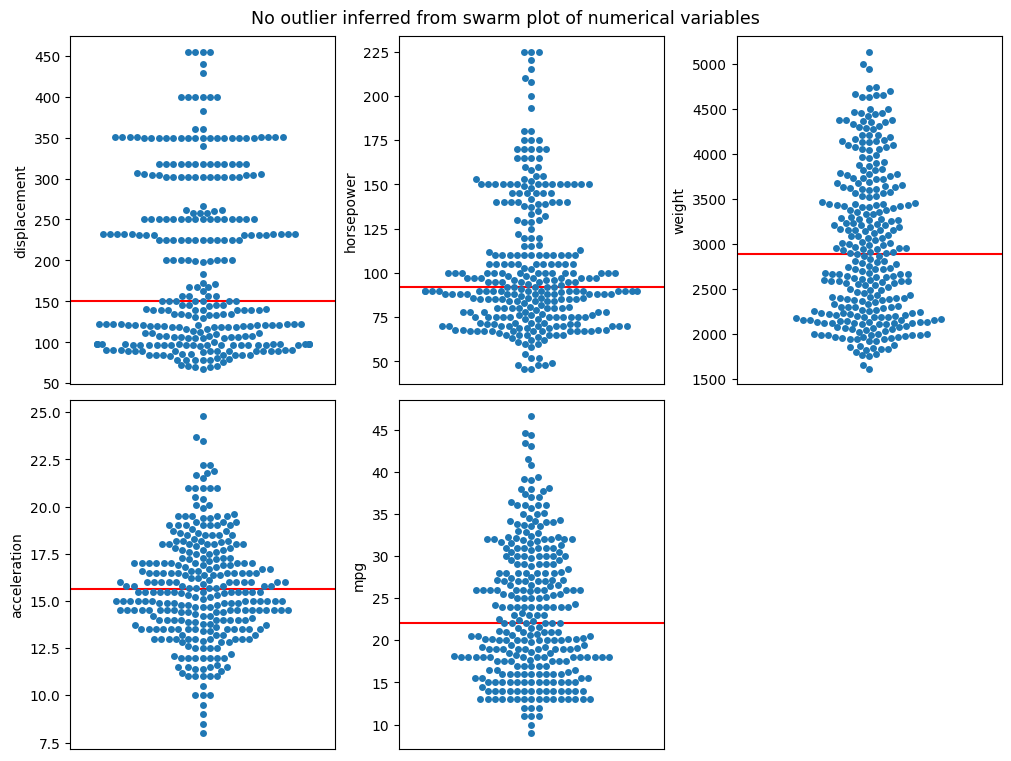

In [14]:
# create & setup plot figure
width, height = 10, 7.5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
suptitle_size = 12.5
plt.suptitle(
    t="No outlier inferred from swarm plot of numerical variables",
    size=suptitle_size
)

# subset columns with numerical data types from data
data_train_numerical = data_train.select_dtypes(include="number")

# plot visualization for numerical data
nrows, ncols = 2, 3
for count, column in enumerate(iterable=data_train_numerical):
    plt.subplot(nrows, ncols, count + 1)

    swarm_plot = sns.swarmplot(
        data=data_train_numerical,
        y=column
    )
    swarm_plot.set_xticks(ticks=list())

    def midpoint_line(midpoint):
        """Draws a horizontal line at a specified midpoint on a plot.
        
        Args:
            midpoint (float): The y-coordinate at which to draw the horizontal line.
        
        Returns:
            matplotlib.lines.Line2D: The line object representing the horizontal line.
        """
        midpoint_line = plt.axhline(
            y=midpoint,
            color="red"
        )
        return midpoint_line

    if column != "acceleration":
        median = data_train_numerical[column].median()
        median_line = midpoint_line(midpoint=median)
    elif column == "acceleration":
        mean = data_train_numerical[column].mean()
        mean_line = midpoint_line(midpoint=mean)

Swarmplot digunakan untuk menunjukkan data points berdasarkan variabel numerik dalam Auto MPG dataset.
* Karena jumlah observasi dalam dataset relatif sedikit, maka swarmplot bermanfaat untuk memvisualkan data points tersebut secara non-overlapping.
* Beberapa insight dapat ditarik dari visualisasi sederhana ini seperti persebaran data, skewness, distribution gaps, hingga modality. Namun fokus analisa ini berada pada [magnitude](https://en.wikipedia.org/wiki/Order_of_magnitude) dan [outlier](https://en.wikipedia.org/wiki/Outlier) pada tiap variabel.
    * Terdeteksi adanya **perbedaan rentang nilai** antar variabel numerikal:
        * Mulai dari rentang satuan pada variabel `acceleration` hingga ribuan pada variabel `weight`.
        * Keragaman nilai ini may pose several problems in machine learning models as explained in further [section](#variable-magnitude).
    * Ambil contoh variabel `displacement`, data points dengan nilai `~450` berada cukup jauh dari midpointnya (red median line) relatif terhadap points lainnya.
        * Meskipun demikian, outside values ini tidak jauh berbeda dengan data points lainnya dan bukanlah sebuah error sebagaimana yang disampaikan pada [Initial Data Inspection](#initial-data-inspection).
        * Sehingga ia dapat didefinisikan sebagai **non-outlier**.

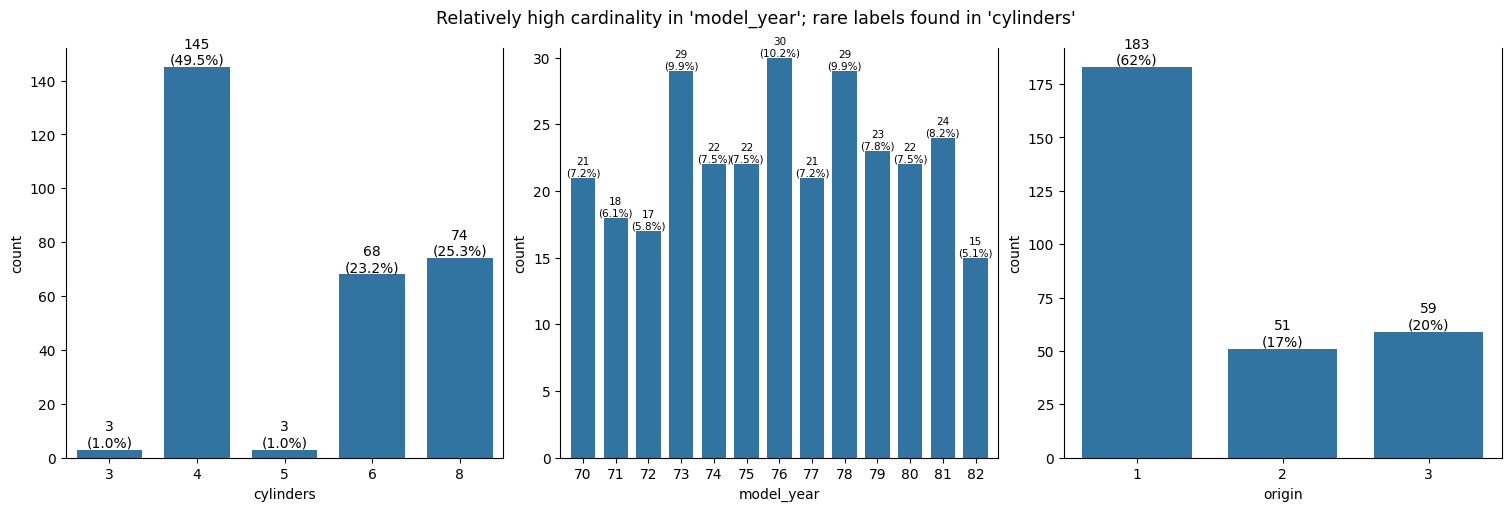

In [ ]:
# create & setup plot figure
width, height = 15, 5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
suptitle_size = 12.5
plt.suptitle(
    t="Relatively high cardinality in 'model_year'; rare labels found in 'cylinders'",
    size=suptitle_size
)

# subset columns with categorical data types from the data
data_train_categorical = data_train.select_dtypes(include="category")

def plot_categorical(data=data_train_categorical, ndigits=None, label_type="edge", fontsize=10):
    """Plot a categorical bar chart with counts and percentages.
    
    This function creates a bar plot for categorical data, displaying both the count and percentage of each category. 
    The counts are shown as bar heights, while the percentages are displayed as labels on the bars.
    
    Args:
        data (DataFrame): The input data containing categorical variables. Default is `data_train_categorical`.
        ndigits (int, optional): The number of decimal places to round the percentage labels. If None, no rounding is applied. Default is None.
        label_type (str): The type of label to display on the bars. Options include 'edge' and 'center'. Default is 'edge'.
        fontsize (int): The font size of the labels on the bars. Default is 10.
    
    Returns:
        Axes: The axes object containing the bar plot.
    """
    plt.subplot(nrows, ncols, count + 1)

    barplot_data = pd.concat(
        objs=[data[column].value_counts().sort_index(),
              data[column].value_counts(normalize=True).mul(other=100)],
        axis=1
    )

    axes = sns.barplot(
        data=barplot_data, 
        x=barplot_data.index,
        y="count",
        width=barplot_width
    )

    labels = [f"{round(value.get_height())}\n({round(number=barplot_data.iloc[index, 1], ndigits=ndigits)}%)"
              for index, value in enumerate(axes.containers[0])]
    
    axes.bar_label(
        container=axes.containers[0], 
        labels=labels,
        label_type=label_type,
        fontsize=fontsize
    )
    axes.spines.top.set_visible(b=False)

    return axes

# plot visualization for categorical data
nrows, ncols = 1, 3
barplot_width = 0.75
for count, column in enumerate(iterable=data_train_categorical):
    if column == "cylinders":
        plot_categorical(ndigits=1)

    elif column == "model_year":
        axes = plot_categorical(
            ndigits=1,
            fontsize=7.5
        )
        axes.margins(0.025)
        
    elif column == "origin":
        plot_categorical()

[Bar chart](https://en.wikipedia.org/wiki/Bar_chart) or bar graph is a chart or graph that presents categorical data with rectangular bars with heights or lengths proportional to the values that they represent.
* The graph shows comparisons among discrete categories.
    * For these particular graphs, one axis of the chart shows the specific categories being compared, and the other axis represents a measured value.
    * Categorical variables are those which values are selected from a group of categories —also called labels.
    * Tiap grafik dalam plot di atas merepresentasikan labels yang berada dalam variabel tertentu dan occurences (count) dari label tersebut.
    * Ambil contoh pada variabel `origin`, labels dengan occurences tertinggi adalah `1` sejumlah `183` observations atau `62%` dari keseluruhan data.

* Different categorical variables contain different number of labels or categories.
    * The variable `origin` contains only 3 labels, but `model_year` has a bigger number of `13` different labels.
    * The number of different labels within a categorical variable is known as cardinality. A high number of labels within a variable is known as **high cardinality**.

* Different labels also appear in the data with different frequencies.
    * Some categories appear a lot, whereas some other categories appear only in a few number of observations.
    * E.g. label `4` in `cylinders` appears `145` times, while the other `3` and `5` labels are named **rare labels** (only appear `3` times for each of them).

### Data Anomaly

<center>

| Category | Insight |
| --- | --- |
| Variable Magnitude | Terdeteksi adanya perbedaan rentang nilai antar variabel numerik dalam dataset |
| Cardinality | Relatively high cardinality in `model_year` with `13` different labels |
| Rare Label | Label `3` and `5` in `cylinders` appear only in `~1%` of total data |

</center>

#### Variable Magnitude

In [16]:
# generate descriptive statistics for numerical variables
data_train_numerical.describe()

,displacement,horsepower,weight,acceleration,mpg
count,293.000000,293.000000,293.000000,293.000000,293.000000
mean,194.148464,103.211604,2988.098976,15.628328,23.426621
std,102.064675,36.860385,835.838383,2.770734,7.883226
min,68.000000,46.000000,1613.000000,8.000000,9.000000
25%,105.000000,76.000000,2230.000000,13.800000,17.000000
50%,151.000000,92.000000,2890.000000,15.500000,22.000000
75%,262.000000,122.000000,3613.000000,17.300000,29.500000
max,455.000000,225.000000,5140.000000,24.800000,46.600000


Descriptive statistics di atas menunjukkan perbedaan rentang nilai antar variabel numerik. Magnitude of the variables matter because of the following reasons:
* In Linear Regression models, the scale of variables used to estimate the output matters. Linear models are of the type $y = wx + b$, where the regression coefficient $w$ represents the expected change in $y$ for a one unit change in $x$ (the predictor).
    * Thus, the magnitude of $w$ is partly determined by the magnitude of the units being used for $x$.
    * If $x$ is a mass variable, just changing the scale from pounds to grams will cause a change in the magnitude of the coefficient.
    * In addition, in situations where user would estimate the outcome $y$ by contemplating multiple predictors $x_1, x_2, ...x_n$, predictors with greater numeric ranges dominate over those with smaller numeric ranges.
* In Support Vector Machines, feature scaling can decrease the time to find the support vectors.
* Finally, methods using Euclidean distances or distances in general are also affected by the magnitude of the features, as Euclidean distance is sensitive to variations in the magnitude or scales of the predictors. Therefore feature scaling is required for methods that utilise distance calculations like K-Nearest Neighbours.

#### Cardinality

In [17]:
def cardinality_inspection(train, test, columns):
    """Generates a summary of unique labels in specified columns for training and testing datasets.
    
    Args:
        train (pd.DataFrame): The training data containing the columns to inspect.
        test (pd.DataFrame): The testing data containing the columns to inspect.
        columns (list of str): A list of column names to analyze for unique labels.
    
    Returns:
        pd.DataFrame: A DataFrame summarizing the unique labels found in the training and testing datasets for each specified column.
                      The DataFrame is indexed by the column names, with each entry containing lists of labels unique to the training data 
                      and those unique to the testing data.
    """
    cardinality_summary = list()
    for column in columns:
        train_only_labels = [label for label in train[column].unique() if label not in test[column].unique()]
        test_only_labels = [label for label in test[column].unique() if label not in train[column].unique()]
        cardinality_summary.append(
            {"column": column,
             "train": train_only_labels,
             "test": test_only_labels}
        )
    df_cardinality_summary = pd.DataFrame(data=cardinality_summary).set_index(keys="column")
    
    return df_cardinality_summary

In [18]:
# perform cardinality inspection
data_categorical = data_train_categorical.copy()

cardinality_inspection(
    train=data_train,
    test=data_test,
    columns=data_categorical.columns
)

,train,test
column,,
cylinders,[5],[]
model_year,[],[]
origin,[],[]


Fungsi `cardinality_inspection` di atas menunjukkan label pada variabel tertentu yang ditemukan hanya pada train ataupun test set.
* Berlawanan dengan yang ditunjukkan pada [`Section 2: Visual Analysis`](#visual-analysis), permasalahan kardinalitas tidak muncul pada variabel `model_year` dengan jumlah label yang relatif lebih besar daripada variabel lainnya, namun
* Hal ini justru ditemukan pada `cylinders` setelah variabel ini dipisah menjadi train dan test sets , yakni label `5` yang hanya ditemukan pada `train`.

High cardinality may pose the following problems: 

* Variables with too many labels tend to dominate over those with only a few labels, particularly in Tree-based algorithms.
* A big number of labels within a variable may introduce noise with little, if any, information, therefore making machine learning models prone to over-fit.
* Some of the labels may only be present in the training data set, but not in the test set, therefore machine learning algorithms may over-fit to the training set.

#### Rare Label

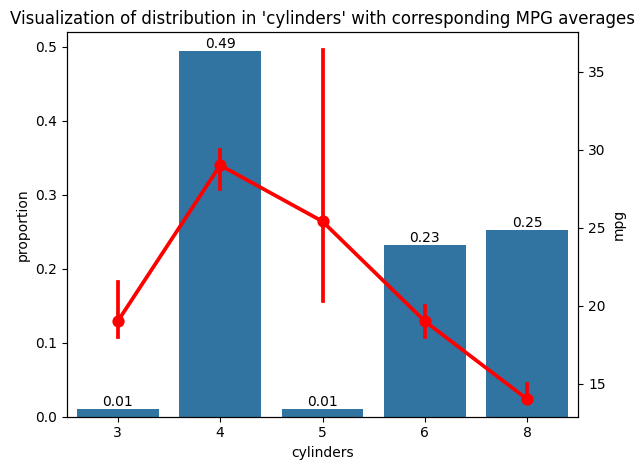

In [19]:
_, ax = plt.subplots(layout='tight')
plt.title(label="Visualization of distribution in 'cylinders' with corresponding MPG averages")

sns.countplot(
    data=data_train,
    x="cylinders",
    stat="proportion",
    ax=ax
)
ax.bar_label(
    container=ax.containers[0],
    fmt='%.2f'
)

ax_twinx = ax.twinx()
sns.pointplot(
    data=data_train,
    x="cylinders",
    y="mpg",
    estimator="median",
    errorbar="ci",
    seed=RANDOM_STATE,
    color="red",
    ax=ax_twinx,
)

plt.show()

Rare label inspection dilakukan khusus pada variabel `cylinders`, sesuai dengan temuan yang didapatkan pada [`Section 2: Visual Analysis`](#visual-analysis).
* Proporsi label `3 & 5` hanya `0.01` atau 1% dari keseluruhan `data_train`. 
    * Jika target `mpg` dikelompokkan berdasarkan labels in this `cylinders` feature, kedua label ini memiliki median value of `mpg` yang berbeda dengan lainnya.
    * And especially on `5`, the confidence interval from [bootstrapping](https://seaborn.pydata.org/tutorial/error_bars.html) is wide, showing a high uncertainty and variability of `mpg` estimate.
    * Dengan proporsi sampel yang sedikit, maka estimasi nilai sebenarnya dari `mpg` terhadap `cylinders` akan diragukan kebenarannya; bisa jadi nilai rerata ini (population average) berada di bawah ataupun di atas rerata sampel.
* Seperti halnya diagnosis pada kardinalitas, rare label issue bisa menyebabkan:
    * Rare values in categorical variables tend to cause over-fitting, particularly in tree based methods.
    * Rare labels may be present in training set, but not in test set, therefore causing over-fitting to the train set.
    * Rare labels may appear in the test set, and not in the train set. Thus, the machine learning model will not know how to evaluate it. 

---

## Section 3 | Feature Engineering

### Standardization

In [20]:
# standardize numerical features in train set
standard_scaler = StandardScaler()
column_transformer = make_column_transformer(
    (standard_scaler, make_column_selector(dtype_include="number")),
    remainder="drop",
    verbose_feature_names_out=False
)
data_train_numerical = pd.DataFrame(
    data=column_transformer.fit_transform(X=data_train),
    columns=column_transformer.get_feature_names_out()
)

Feature scaling through [standardization](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html#sphx-glr-auto-examples-preprocessing-plot-scaling-importance-py) —also called Z-score normalization— is an important preprocessing step for many machine learning algorithms.
* Standardization of datasets is a [common requirement](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling) for many machine learning estimators implemented in scikit-learn.
* They might behave badly if the individual features do not more or less look like standard normally distributed data: Gaussian with zero mean and unit variance, sebagaimana ditunjukkan berikut ini.

In [21]:
# inspect variable magnitudes after standardization
data_train_numerical.describe()

,displacement,horsepower,weight,acceleration,mpg
count,2.930000e+02,2.930000e+02,2.930000e+02,2.930000e+02,2.930000e+02
mean,1.212530e-17,-1.818795e-16,-6.062651e-17,-2.425061e-16,-4.850121e-17
std,1.001711e+00,1.001711e+00,1.001711e+00,1.001711e+00,1.001711e+00
min,-1.238081e+00,-1.554772e+00,-1.647988e+00,-2.757889e+00,-1.833171e+00
25%,-8.749451e-01,-7.394974e-01,-9.085440e-01,-6.610001e-01,-8.166221e-01
50%,-4.234794e-01,-3.046844e-01,-1.175668e-01,-4.639463e-02,-1.812788e-01
75%,6.659270e-01,5.105899e-01,7.489129e-01,6.043641e-01,7.717361e-01
max,2.560120e+00,3.309699e+00,2.578947e+00,3.315859e+00,2.944610e+00


* Setelah melalui standarisasi, tiap variabel numerik dalam data memiliki `mean` yang mendekati nol. Serta `std` dalam satuan unit yang serupa.
* Proses ini juga meratakan order of the magnitude, sehingga nilai tiap variabel berada pada rentang nilai satuan —or within about a factor of 10 from each other.

### Drop Rare Labels

In [22]:
class DropLabelsTransformer(BaseEstimator, TransformerMixin):
    """Custom scikit-learn transformer that removes specified labels from a given column in a DataFrame.
    Useful for preprocessing data by eliminating unwanted categories before further analysis or modeling.
    
    Attributes:
        column (str): The name of the column from which labels will be dropped.
        labels_to_drop (list): A list of labels to be removed from the specified column.
        feature_names_in_ (numpy.ndarray): The feature names of the input DataFrame after fitting.
    
    Methods:
        fit(X, y=None):
            Fits the transformer to the data, storing the feature names.
        
        transform(X):
            Transforms the input DataFrame by dropping the specified labels from the column.
        
        get_feature_names_out():
            Returns the feature names of the transformed DataFrame.
        
    Args:
        column (str): The name of the column to process.
        labels_to_drop (list): The labels to drop from the specified column.
    """
    def __init__(self, column, labels_to_drop):
        self.column = column
        self.labels_to_drop = labels_to_drop

    def fit(self, X, y=None):
        self.feature_names_in_ = X.columns.to_numpy()
        return self

    def transform(self, X):
        X = X.copy()
        row_mask = X[self.column].isin(self.labels_to_drop)
        X_transformed = X.loc[~row_mask].reset_index(drop=True)
        X_transformed[self.column] = X_transformed[self.column].astype("category").cat.remove_unused_categories()
        return X_transformed

    def get_feature_names_out(self):
        return self.feature_names_in_

In [23]:
# drop rare labels from 'cylinders' variable in train data
drop_labels_transformer = DropLabelsTransformer(
    column="cylinders",
    labels_to_drop=[3, 5]
)
data_train = drop_labels_transformer.fit_transform(X=data_train)
data_test = drop_labels_transformer.transform(X=data_test)

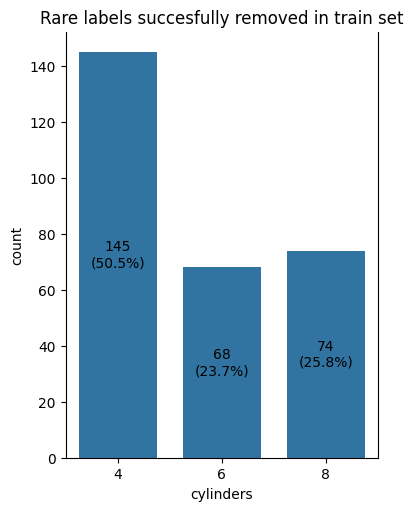

In [29]:
# inspect rare labels after removal
width, height = 10, 5
plt.figure(
    figsize=(width, height),
    layout="constrained"
)
for count, column in enumerate(iterable=data_categorical):
    if column == "cylinders":
        axes = plot_categorical(
            data=data_train,
            ndigits=1,
            label_type="center"
        )
        axes.set_title(label="Rare labels succesfully removed in train set",)
    else:
        pass

### Feature Encoding

In [25]:
onehot_encoder = OneHotEncoder(sparse_output=False)
column_transformer = make_column_transformer(
    (onehot_encoder, make_column_selector(dtype_include="category")),
    remainder="drop",
    verbose_feature_names_out=False
)

data_train_categorical = pd.DataFrame(
    data=column_transformer.fit_transform(X=data_train),
    columns=column_transformer.get_feature_names_out()
)
data_test_categorical = pd.DataFrame(
    data=column_transformer.transform(X=data_test),
    columns=column_transformer.get_feature_names_out()
)

In [26]:
cardinality_inspection(
    train=data_train_categorical,
    test=data_test_categorical,
    columns=[feature for feature in column_transformer.get_feature_names_out()]
)

,train,test
column,,
cylinders_4,[],[]
cylinders_6,[],[]
cylinders_8,[],[]
model_year_70,[],[]
model_year_71,[],[]
model_year_72,[],[]
model_year_73,[],[]
model_year_74,[],[]
model_year_75,[],[]


---

## Reference

* Quinlan, R. (1993). Combining Instance-Based and Model-Based Learning. *In Proceedings on the Tenth International Conference of Machine Learning*, 236-243, University of Massachusetts, Amherst: Morgan Kaufmann.
* Little, R. J. A. (1988). A Test of Missing Completely at Random for Multivariate Data with Missing Values. *Journal of the American Statistical Association, 83*(404), 1198–1202. https://doi.org/10.1080/01621459.1988.10478722
* Tukey, J. W. (1977). *Exploratory Data Analysis*. Reading, Massachusetts: Addison-Wesley.
* Hawkins, D. (2013). *Identification of Outliers*. Netherlands: Chapman and Hall.